# LLM-as-judge label audit — RelAmazon

This notebook inspects the seven model annotation files for the v2 signal-relevance prompt. It reports label coverage and distributions, compares models on condition–signal pairs they both judged, and surfaces disagreements for review.

Agreement is not accuracy: without human relevance judgments, these comparisons show consistency/strictness, not which model is correct. A failed or unjudgeable response is kept distinct from grade 0.

In [75]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("/storage/lcostes/Similarity_benchmark/annotations/llm-judged/rel-amazon/signal-relevance-v2")

MODEL_ORDER = [
    "gemma-4-31b",
    "glm-4.7-flash",
    "mistral-small-3.2",
    "muse-glimmer-30b",
    "qwen3.6-35b-a3b-fp8",
    "qwen3.8-27b-fp8-low",
    "qwen3.8-27b-fp8-high",
]

files = sorted(DATA_DIR.glob("*.jsonl"))
if not files:
    raise FileNotFoundError(f"No JSONL label files found in {DATA_DIR}")

frames = []
for path in files:
    frame = pd.read_json(path, lines=True)
    frame["model"] = path.stem
    frames.append(frame)

labels = pd.concat(frames, ignore_index=True, sort=False)
labels["grade"] = pd.to_numeric(labels.get("grade"), errors="coerce")
labels["status"] = labels.get("status", pd.Series("unknown", index=labels.index)).fillna("unknown").astype(str)
labels["condition_id"] = labels.get("condition_id", pd.Series("", index=labels.index)).fillna("").astype(str)
labels["candidate_id"] = labels.get("candidate_id", pd.Series("", index=labels.index)).fillna("").astype(str)
labels["pair_id"] = labels["condition_id"] + "::" + labels["candidate_id"]

models_found = [m for m in MODEL_ORDER if m in set(labels["model"])]
models_found += sorted(set(labels["model"]) - set(models_found))
print(f"Loaded {len(labels):,} rows from {len(files)} model file(s)")
print("Models:", ", ".join(models_found))
print("Prompt versions:", sorted(labels.get("prompt_version", pd.Series(dtype=str)).dropna().astype(str).unique()))
print("Data directory:", DATA_DIR)

Loaded 1,365 rows from 7 model file(s)
Models: gemma-4-31b, glm-4.7-flash, mistral-small-3.2, muse-glimmer-30b, qwen3.6-35b-a3b-fp8, qwen3.8-27b-fp8-low, qwen3.8-27b-fp8-high
Prompt versions: ['signal-relevance-v2']
Data directory: /storage/lcostes/Similarity_benchmark/annotations/llm-judged/rel-amazon/signal-relevance-v2


## 1. Coverage and response validity

Only rows with `status == "judged"` and an integer grade from 0 to 3 enter grade-distribution and agreement analyses. Unjudgeable, malformed, or failed outputs are coverage issues—not negative relevance labels.

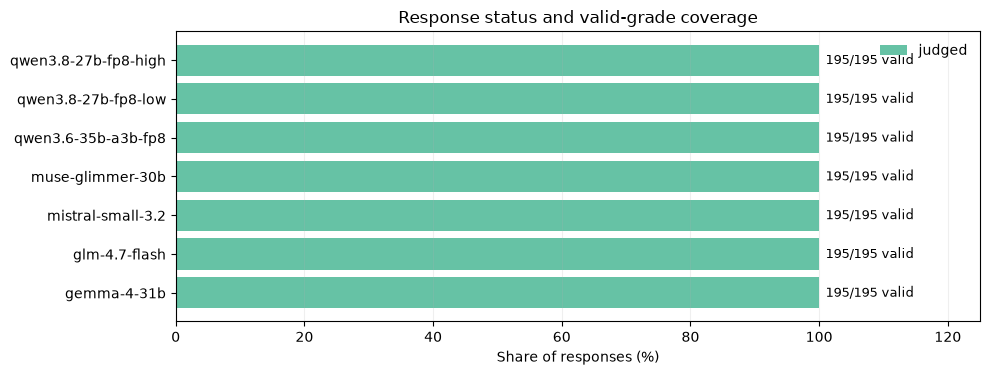

In [76]:
status_counts = (
    labels.groupby(["model", "status"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .reindex(models_found)
)
status_counts["total"] = status_counts.sum(axis=1)
judged_valid = labels["status"].eq("judged") & labels["grade"].isin([0, 1, 2, 3])
valid_counts = labels[judged_valid].groupby("model").size().reindex(models_found, fill_value=0)
status_counts["valid graded"] = valid_counts
status_counts["valid graded %"] = (100 * status_counts["valid graded"] / status_counts["total"]).round(1)
status_columns = [c for c in status_counts.columns if c not in {"total", "valid graded", "valid graded %"}]
status_pct = status_counts[status_columns].div(status_counts["total"].replace(0, np.nan), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, max(3.5, 0.55 * len(models_found))))
left = np.zeros(len(status_pct))
status_colors = plt.get_cmap("Set2").colors
for i, status in enumerate(status_columns):
    values = status_pct[status].fillna(0).to_numpy()
    ax.barh(status_pct.index, values, left=left, label=status, color=status_colors[i % len(status_colors)])
    left += values
for y, model in enumerate(status_pct.index):
    ax.text(101, y, f"{int(status_counts.loc[model, 'valid graded'])}/{int(status_counts.loc[model, 'total'])} valid", va="center", fontsize=9)
ax.set_xlim(0, 125)
ax.set_xlabel("Share of responses (%)")
ax.set_title("Response status and valid-grade coverage")
ax.legend(frameon=False, ncol=max(1, len(status_columns)))
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 2. Grade distribution by model

Grades are treated as ordinal relevance judgments (0–3). The normalized chart makes model strictness easier to compare even if row coverage differs.

Grades meaning:
- 0 -> Irrelevant 
- 1 -> Weak or indirect relevance
- 2 -> Useful, but not central
- 3 -> Directly relevant or central to the intent

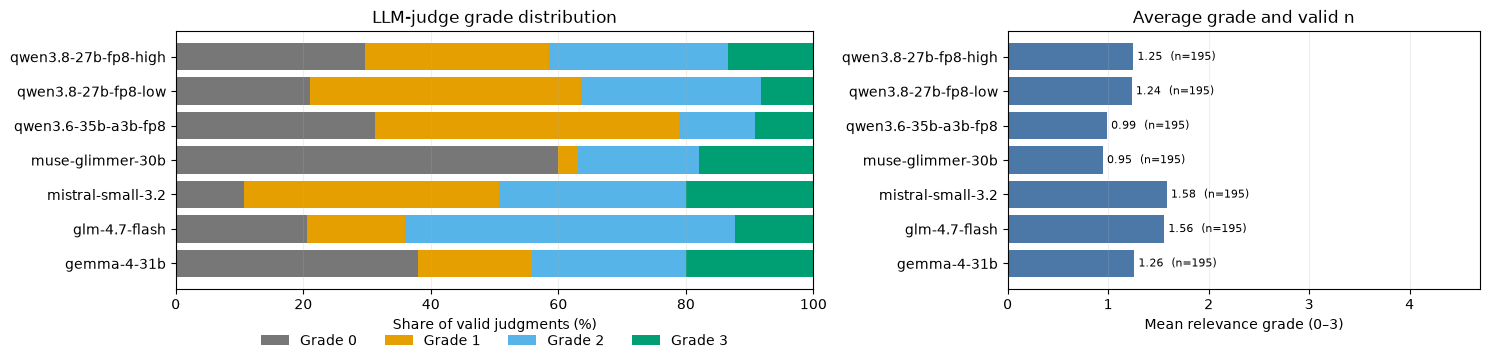

In [77]:
valid = labels[judged_valid].copy()
grade_counts = (
    valid.groupby(["model", "grade"]).size()
    .unstack(fill_value=0)
    .reindex(index=models_found, columns=[0, 1, 2, 3], fill_value=0)
)
grade_pct = grade_counts.div(grade_counts.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, (ax, ax_mean) = plt.subplots(1, 2, figsize=(15, max(3.5, 0.55 * len(models_found))), gridspec_kw={"width_ratios": [1.35, 1]})
left = np.zeros(len(grade_pct))
colors = ["#777777", "#e69f00", "#56b4e9", "#009e73"]
for grade, color in zip([0, 1, 2, 3], colors):
    vals = grade_pct[grade].fillna(0).to_numpy()
    ax.barh(grade_pct.index, vals, left=left, label=f"Grade {grade}", color=color)
    left += vals
ax.set_xlim(0, 100)
ax.set_xlabel("Share of valid judgments (%)")
ax.set_title("LLM-judge grade distribution")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.28), frameon=False)
ax.grid(axis="x", alpha=0.2)
mean_grade = valid.groupby("model")["grade"].mean().reindex(models_found)
n_per_model = grade_counts.sum(axis=1).reindex(models_found)
ax_mean.barh(models_found, mean_grade, color="#4c78a8")
ax_mean.set_xlim(0, 4.7)
ax_mean.set_xlabel("Mean relevance grade (0–3)")
ax_mean.set_title("Average grade and valid n")
for y, model in enumerate(models_found):
    ax_mean.text(mean_grade.loc[model] + 0.04, y, f"{mean_grade.loc[model]:.2f}  (n={int(n_per_model.loc[model])})", va="center", fontsize=8)
ax_mean.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Pairwise agreement on shared pairs

For each model pair, the notebook uses only condition–signal pairs with valid grades from both models. Metrics:

- **Exact agreement:** fraction of pairs receiving the same 0–3 grade.
- **Quadratic weighted κ:** chance-corrected ordinal agreement. It is 1 for perfect agreement, about 0 when agreement is no better than expected by chance, and can be negative when it is worse. A one-grade difference is penalized less than a two- or three-grade difference.
- **Binary agreement (grade ≥2):** the share of pairs where both models make the same broad call: grades 0–1 versus grades 2–3. It ignores differences within each group (for example, 2 versus 3 counts as agreement).
- **Mean absolute grade gap:** average distance on the 0–3 scale.

Pair counts matter: agreement estimates are comparable only when their shared coverage is similar.

In [78]:
def quadratic_weighted_kappa(a, b, n_grades=4):
    a = np.asarray(a, dtype=int)
    b = np.asarray(b, dtype=int)
    if len(a) == 0:
        return np.nan
    observed = np.zeros((n_grades, n_grades), dtype=float)
    for x, y in zip(a, b):
        observed[x, y] += 1
    observed /= len(a)
    expected = np.outer(np.bincount(a, minlength=n_grades), np.bincount(b, minlength=n_grades)).astype(float)
    expected /= max(1, len(a) ** 2)
    levels = np.arange(n_grades)
    weights = ((levels[:, None] - levels[None, :]) / (n_grades - 1)) ** 2
    denom = np.sum(weights * expected)
    return np.nan if denom == 0 else 1 - np.sum(weights * observed) / denom

wide = valid.pivot_table(index="pair_id", columns="model", values="grade", aggfunc="first")
pairwise_rows = []
for i, model_a in enumerate(models_found):
    for model_b in models_found[i + 1:]:
        if model_a not in wide or model_b not in wide:
            continue
        both = wide[[model_a, model_b]].dropna()
        if both.empty:
            continue
        a = both[model_a].astype(int).to_numpy()
        b = both[model_b].astype(int).to_numpy()
        pairwise_rows.append({
            "model A": model_a,
            "model B": model_b,
            "shared pairs": len(both),
            "exact agreement": np.mean(a == b),
            "weighted kappa": quadratic_weighted_kappa(a, b),
            "binary agreement (grade ≥2)": np.mean((a >= 2) == (b >= 2)),
            "mean |grade gap|": np.mean(np.abs(a - b)),
        })
pairwise = pd.DataFrame(pairwise_rows, columns=["model A", "model B", "shared pairs", "exact agreement", "weighted kappa", "binary agreement (grade ≥2)", "mean |grade gap|"])
if pairwise.empty:
    print("No model pairs have overlapping valid judgments yet.")
else:
    print(f"Pairwise model-pair metrics — sorted by weighted κ, then shared-pair count")
    display(pairwise.sort_values(["weighted kappa", "shared pairs"], ascending=[False, False]).round(3))

Pairwise model-pair metrics — sorted by weighted κ, then shared-pair count


,model A,model B,shared pairs,exact agreement,weighted kappa,binary agreement (grade ≥2),mean |grade gap|
20,qwen3.8-27b-fp8-low,qwen3.8-27b-fp8-high,195,0.749,0.862,0.887,0.251
4,gemma-4-31b,qwen3.8-27b-fp8-low,195,0.513,0.726,0.841,0.518
5,gemma-4-31b,qwen3.8-27b-fp8-high,195,0.544,0.722,0.790,0.523
18,qwen3.6-35b-a3b-fp8,qwen3.8-27b-fp8-low,195,0.605,0.722,0.805,0.410
3,gemma-4-31b,qwen3.6-35b-a3b-fp8,195,0.549,0.721,0.749,0.508
19,qwen3.6-35b-a3b-fp8,qwen3.8-27b-fp8-high,195,0.579,0.698,0.764,0.467
14,mistral-small-3.2,qwen3.8-27b-fp8-high,195,0.513,0.683,0.800,0.538
13,mistral-small-3.2,qwen3.8-27b-fp8-low,195,0.533,0.653,0.800,0.513
2,gemma-4-31b,muse-glimmer-30b,195,0.590,0.644,0.785,0.600
1,gemma-4-31b,mistral-small-3.2,195,0.472,0.608,0.774,0.641


### Pairwise metric heatmaps and model-to-peer summary

The heatmaps show ordinal agreement, exact and binary agreement, average grade gap, and the number of shared pairs. Blank cells indicate no shared valid judgments. The bars below aggregate each model’s comparisons against all peers: lower mean grade gap and higher weighted κ indicate greater overall similarity to the other judges.

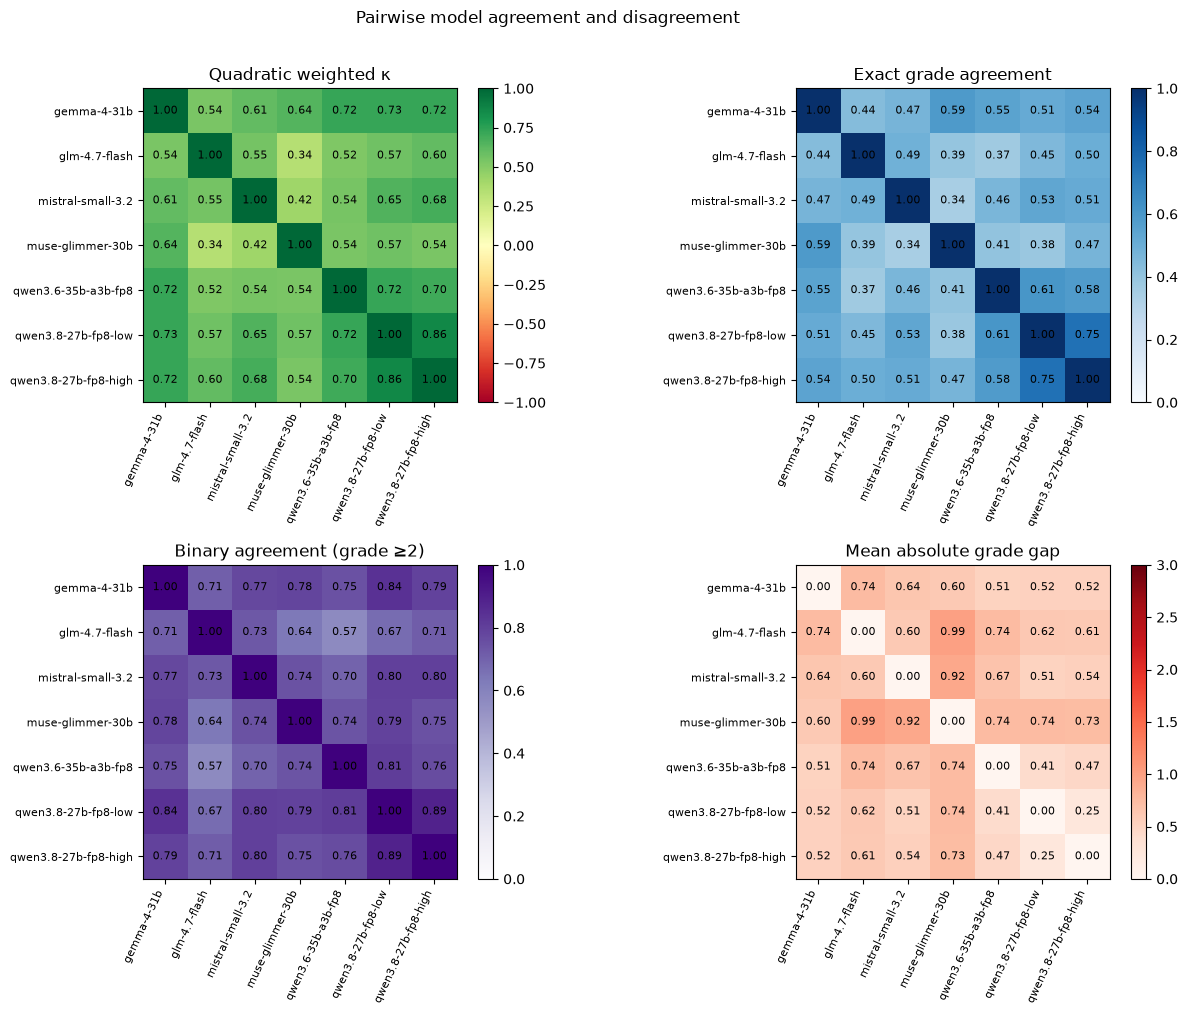

Model similarity to all peers — sorted by mean absolute grade gap (lower means closer)


,similarity rank,peer comparisons,mean absolute grade gap (lower = closer),mean weighted κ (higher = closer),mean binary agreement
model,,,,,
qwen3.8-27b-fp8-low,1,6,0.509,0.683,0.799
qwen3.8-27b-fp8-high,2,6,0.520,0.684,0.784
gemma-4-31b,3,6,0.588,0.660,0.774
qwen3.6-35b-a3b-fp8,4,6,0.589,0.624,0.721
mistral-small-3.2,5,6,0.647,0.576,0.757
glm-4.7-flash,6,6,0.716,0.521,0.671
muse-glimmer-30b,7,6,0.787,0.508,0.740


In [79]:
def symmetric_metric_matrix(metric):
    matrix = pd.DataFrame(np.nan, index=models_found, columns=models_found)
    if metric == "mean |grade gap|":
        diagonal = 0.0
    else:
        diagonal = 1.0
    for model in models_found:
        matrix.loc[model, model] = diagonal
    if not pairwise.empty:
        for _, row in pairwise.iterrows():
            matrix.loc[row["model A"], row["model B"]] = row[metric]
            matrix.loc[row["model B"], row["model A"]] = row[metric]
    return matrix

metric_specs = [
    ("weighted kappa", "Quadratic weighted κ", -1, 1, "RdYlGn"),
    ("exact agreement", "Exact grade agreement", 0, 1, "Blues"),
    ("binary agreement (grade ≥2)", "Binary agreement (grade ≥2)", 0, 1, "Purples"),
    ("mean |grade gap|", "Mean absolute grade gap", 0, 3, "Reds"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (metric, title, vmin, vmax, cmap) in zip(axes.flat, metric_specs):
    matrix = symmetric_metric_matrix(metric)
    image = ax.imshow(matrix.to_numpy(dtype=float), vmin=vmin, vmax=vmax, cmap=cmap)
    ax.set_xticks(range(len(models_found)), models_found, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(models_found)), models_found, fontsize=8)
    ax.set_title(title)
    for r in range(len(models_found)):
        for c in range(len(models_found)):
            value = matrix.iloc[r, c]
            if pd.notna(value):
                ax.text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.suptitle("Pairwise model agreement and disagreement", y=1.01)
plt.tight_layout()
plt.show()

# Aggregate each judge's pairwise differences from all its peers.
peer_rows = []
for model in models_found:
    peers = pairwise[(pairwise["model A"] == model) | (pairwise["model B"] == model)]
    peer_rows.append({
        "model": model,
        "peer comparisons": len(peers),
        "average grade gap to peers": peers["mean |grade gap|"].mean(),
        "average weighted κ with peers": peers["weighted kappa"].mean(),
        "average binary agreement with peers": peers["binary agreement (grade ≥2)"].mean(),
    })
peer_summary = pd.DataFrame(peer_rows).set_index("model").reindex(models_found)
peer_summary_display = peer_summary.sort_values("average grade gap to peers", ascending=True).copy()
print("Model similarity to all peers — sorted by mean absolute grade gap (lower means closer)")
peer_summary_display.insert(0, "similarity rank", np.arange(1, len(peer_summary_display) + 1))
display(peer_summary_display.rename(columns={
    "average grade gap to peers": "mean absolute grade gap (lower = closer)",
    "average weighted κ with peers": "mean weighted κ (higher = closer)",
    "average binary agreement with peers": "mean binary agreement",
}).round(3))

In [80]:
from IPython.display import clear_output, display, Markdown

# Show only maximum-gap pairs: at least one judge gave 0 and another gave 3.
disagreement_rows = []
for pair_id, grades in wide.iterrows():
    grades = grades.dropna().astype(int)
    if len(grades) < 2:
        continue
    low, high = int(grades.min()), int(grades.max())
    if high - low != 3:
        continue
    pair_labels = valid[valid["pair_id"].eq(pair_id)]
    item = pair_labels.iloc[0]
    candidate = item.get("candidate")
    description = candidate.get("description", str(candidate)) if isinstance(candidate, dict) else str(candidate)
    disagreement_rows.append({
        "pair_id": pair_id,
        "condition_id": item.get("condition_id"),
        "condition": item.get("condition"),
        "candidate_id": item.get("candidate_id"),
        "signal": description,
        "grade gap": high - low,
        "extreme 0 vs 3": low == 0 and high == 3,
        "grades by model": grades.to_dict(),
    })

disagreements = pd.DataFrame(disagreement_rows)
if disagreements.empty:
    print("No shared pairs have the maximum 3-point grade gap (0 versus 3).")
else:
    disagreements = disagreements.sort_values(["extreme 0 vs 3", "grade gap"], ascending=False).reset_index(drop=True)
    print(f"{len(disagreements)} pair(s) have the maximum 3-point gap (one or more models graded 0 and another graded 3).")
    try:
        import ipywidgets as widgets
    except ImportError:
        widgets = None

    def show_disagreement(index):
        pair = disagreements.iloc[int(index)]
        pair_labels = valid[valid["pair_id"].eq(pair["pair_id"])].sort_values(["grade", "model"], ascending=[True, True])
        display(Markdown(f"## {pair['condition_id']} — {pair['candidate_id']}\n\n**Intent:** {pair['condition']}\n\n**Signal:** {pair['signal']}\n\n**Grade spread:** {pair['grade gap']} point(s)\n\n**Grades by model:** {pair['grades by model']}"))
        for _, judgment in pair_labels.iterrows():
            reason = judgment.get("reason")
            if pd.isna(reason) or not str(reason).strip():
                reason = "(No rationale saved.)"
            display(Markdown(f"### {judgment['model']} — Grade {int(judgment['grade'])}\n\n{reason}"))

    if widgets is None:
        print("ipywidgets is unavailable; call show_disagreement(0), show_disagreement(1), etc. to browse.")
        show_disagreement(0)
    else:
        selector = widgets.Dropdown(
            options=[(f"{i + 1}. {'0-vs-3' if row['extreme 0 vs 3'] else 'gap ' + str(row['grade gap'])} | {row['condition_id']} | {row['candidate_id']}", i) for i, row in disagreements.iterrows()],
            description="Pair:",
            layout=widgets.Layout(width="95%"),
        )
        detail_output = widgets.Output()

        def _render_selected(change=None):
            with detail_output:
                clear_output(wait=True)
                show_disagreement(selector.value)

        selector.observe(_render_selected, names="value")
        display(selector, detail_output)
        _render_selected()

24 pair(s) have the maximum 3-point gap (one or more models graded 0 and another graded 3).


Dropdown(description='Pair:', layout=Layout(width='95%'), options=(('1. 0-vs-3 | condition-001 | attribute:cus…

Output()

## Majority-vote consensus and model comparison

For each condition–signal pair, use a strict majority when one exists. Otherwise, resolve a split by choosing the grade with the smallest **total absolute distance** from all model grades (an ordinal medoid). For example, votes 0, 1, 1, 1, 2, 2, 2 resolve to grade 1 because the total grade distance is smaller than for grade 2. If multiple grades have the same minimum distance, consensus remains unresolved. The table compares each model with the all-model consensus, which includes that model’s own vote and is therefore descriptive rather than an independent accuracy measure.

Consensus resolved for 195/195 pairs (40 by ordinal-distance tie-break); remaining pairs have an exact distance tie.


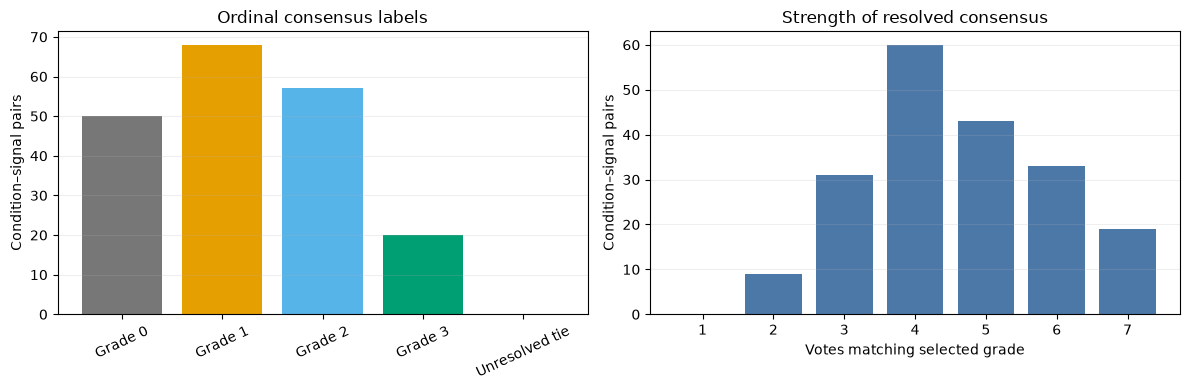

Individual-model metrics versus all-model consensus — sorted by exact agreement, then weighted κ


,pairs,exact agreement,weighted kappa,binary agreement (grade ≥2),mean |grade gap|
model,,,,,
qwen3.8-27b-fp8-low,195,0.821,0.892,0.938,0.179
qwen3.8-27b-fp8-high,195,0.785,0.890,0.897,0.215
qwen3.6-35b-a3b-fp8,195,0.692,0.799,0.815,0.323
gemma-4-31b,195,0.646,0.836,0.882,0.359
mistral-small-3.2,195,0.636,0.740,0.862,0.405
glm-4.7-flash,195,0.549,0.650,0.723,0.523
muse-glimmer-30b,195,0.472,0.632,0.810,0.651


In [ ]:
def ordinal_vote_consensus(votes):
    votes = pd.Series(votes).dropna().astype(int)
    if votes.empty:
        return None, 0, 0, "no votes"
    counts = votes.value_counts()
    top_grade, top_count = int(counts.index[0]), int(counts.iloc[0])
    if top_count > len(votes) / 2:
        grade, method = top_grade, "strict majority"
    else:
        losses = {grade: int(np.abs(votes.to_numpy() - grade).sum()) for grade in range(4)}
        min_loss = min(losses.values())
        winners = [grade for grade, loss in losses.items() if loss == min_loss]
        if len(winners) == 1:
            grade, method = winners[0], "ordinal-distance tie-break"
        else:
            grade, method = None, "unresolved distance tie"
    support = int(counts.get(grade, 0)) if grade is not None else top_count
    return grade, support, len(votes), method

consensus_rows = []
for pair_id, grade_row in wide.iterrows():
    consensus_grade, votes_for_grade, n_votes, method = ordinal_vote_consensus(grade_row)
    consensus_rows.append({
        "pair_id": pair_id,
        "consensus grade": consensus_grade,
        "votes for consensus": votes_for_grade,
        "valid judges": n_votes,
        "consensus method": method,
    })
all_model_consensus = pd.DataFrame(consensus_rows).set_index("pair_id")
n_consensus = int(all_model_consensus["consensus grade"].notna().sum())
n_distance_resolved = int(all_model_consensus["consensus method"].eq("ordinal-distance tie-break").sum())
print(f"Consensus resolved for {n_consensus}/{len(all_model_consensus)} pairs ({n_distance_resolved} by ordinal-distance tie-break); remaining pairs have an exact distance tie.")
consensus_detail = wide.add_prefix("grade: ").join(all_model_consensus).reset_index()
consensus_labels = all_model_consensus["consensus grade"].map(lambda g: f"Grade {int(g)}" if pd.notna(g) else "Unresolved tie")
consensus_order = ["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Unresolved tie"]
consensus_counts = consensus_labels.value_counts().reindex(consensus_order, fill_value=0)
vote_strength = all_model_consensus.loc[all_model_consensus["consensus grade"].notna(), "votes for consensus"].value_counts().reindex(range(1, len(models_found) + 1), fill_value=0)
fig, (ax_consensus, ax_strength) = plt.subplots(1, 2, figsize=(12, 4))
ax_consensus.bar(consensus_counts.index, consensus_counts.values, color=["#777777", "#e69f00", "#56b4e9", "#009e73", "#bdbdbd"])
ax_consensus.set_title("Ordinal consensus labels")
ax_consensus.set_ylabel("Condition–signal pairs")
ax_consensus.tick_params(axis="x", rotation=25)
ax_consensus.grid(axis="y", alpha=0.2)
ax_strength.bar(vote_strength.index.astype(str), vote_strength.values, color="#4c78a8")
ax_strength.set_title("Strength of resolved consensus")
ax_strength.set_xlabel("Votes matching selected grade")
ax_strength.set_ylabel("Condition–signal pairs")
ax_strength.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

def agreement_summary(predicted, reference):
    paired = pd.DataFrame({"predicted": predicted, "reference": reference}).dropna().astype(int)
    if paired.empty:
        return {"pairs": 0, "exact agreement": np.nan, "weighted kappa": np.nan, "binary agreement (grade ≥2)": np.nan, "mean |grade gap|": np.nan}
    a, b = paired["predicted"].to_numpy(), paired["reference"].to_numpy()
    return {
        "pairs": len(paired),
        "exact agreement": np.mean(a == b),
        "weighted kappa": quadratic_weighted_kappa(a, b),
        "binary agreement (grade ≥2)": np.mean((a >= 2) == (b >= 2)),
        "mean |grade gap|": np.mean(np.abs(a - b)),
    }

consensus_comparison_rows = []
for model in models_found:
    metrics = agreement_summary(wide[model], all_model_consensus["consensus grade"])
    consensus_comparison_rows.append({"model": model, **metrics})
consensus_comparison = pd.DataFrame(consensus_comparison_rows).set_index("model")
consensus_comparison = consensus_comparison.sort_values(["exact agreement", "weighted kappa"], ascending=[False, False])
print("## Individual-model metrics versus all-model consensus — sorted by exact agreement, then weighted κ")
display(consensus_comparison.round(3))

# Summarize exact-distance ties that remain unresolved.
unresolved = all_model_consensus[all_model_consensus["consensus grade"].isna()].copy()
if not unresolved.empty:
    unresolved_max_votes = [int(wide.loc[pair_id].dropna().astype(int).value_counts().max()) for pair_id in unresolved.index]
    split_counts = pd.Series(unresolved_max_votes).value_counts().reindex(range(1, len(models_found) + 1), fill_value=0)
    print(f"{len(unresolved)} pair(s) remain unresolved because multiple grades have the same minimum total distance.")
    plt.figure(figsize=(7, 3.5))
    plt.bar(split_counts.index.astype(str), split_counts.values, color="#9c755f")
    plt.xlabel("Largest vote count received by any one grade")
    plt.ylabel("Unresolved pairs")
    plt.title("Vote concentration among unresolved pairs")
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()